In [1]:
# Standard Library
import warnings
import xml.etree.ElementTree as ET

# Scientific & Numerical
import numpy as np
from scipy.ndimage import generic_filter
from scipy.stats import mode

# Machine Learning
from sklearn import cluster
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_samples,
    silhouette_score,
    rand_score,
    adjusted_rand_score,
    mutual_info_score,
    adjusted_mutual_info_score,
    calinski_harabasz_score,
    davies_bouldin_score,
)
from sklearn.preprocessing import minmax_scale
from yellowbrick.cluster import KElbowVisualizer

from minisom import MiniSom

# Deep Learning (TensorFlow / Keras)
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.regularizers import l1

# Geospatial
from osgeo import gdal, osr
import rioxarray as rxr

# Visualization
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Progress Bar
from tqdm import tqdm

# Warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)  # Suppress runtime warnings


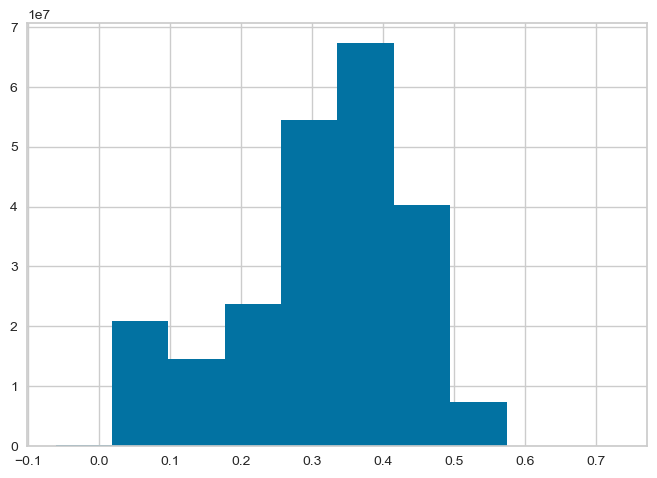

In [2]:
# load the data 
#(rioxarray library that opens raster/geospatial image files (like GeoTIFF, NetCDF, etc.) 
# and loads them as xarray DataArrays with geospatial metadata intact.)
# .squeeze() removes dimensions of size 1 from an array or DataArray.
data_enmap = rxr.open_rasterio('Datasets/ENMAP01-____L2A-DT0000160657_20251016T011429Z_002_V010502_20251017T031330Z-SPECTRAL_IMAGE.TIF').squeeze()

# Replace fill values with NaN
data_enmap = data_enmap.where(data_enmap != -32768)

# Scale to reflectance (0-1 range) - scaled by 10000
data_enmap = data_enmap / 10000.0

data_enmap.plot()
plt.title('')
plt.show()

In [3]:
data_enmap

<xarray.DataArray (band: 224, y: 1182, x: 1223)> Size: 1GB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], dtype=float32)
Coordinates:
  * band         (band) int64 2kB 1 2 3 4 5 6 7 ... 218 219 220 221 222 223 224
  * x            (x) float64 10kB 5.671e+05 5.671e+05 ... 6.037e+05 6.038e+05
  * y            (y) float64 9kB 6.748e+06 6.748e+06 ... 6.712e+06 6.712e+06
    spatial_ref  int64 8B 0

In [4]:
data_enmap.values.shape

(224, 1182, 1223)

In [5]:
# # Convert coordinates to decimal degrees (approximate)
# crop_min_lat = -29.81  # Southernmost point (29° 48' 37" S)
# crop_max_lat = -29.34  # Northernmost point (29° 20' 17" S)
# crop_min_lon = 141.61  # Westernmost point (141° 36' 22" E)  
# crop_max_lon = 142.15  # Easternmost point (142° 08' 47" E)

# #Center Point
# # Latitude: -29.575° (29°34'30" S)
# # Longitude: 141.88° (141°52'48" E)

In [6]:
# # Crop directly with lat/lon bounds (rioxarray handles the transformation)
# data_cropped = data_enmap.rio.clip_box(
#     minx=crop_min_lon,
#     miny=crop_min_lat,
#     maxx=crop_max_lon,
#     maxy=crop_max_lat,
#     crs="EPSG:3308"  # Specify that your bounds are in lat/lon
# )

# data_cropped.plot()
# plt.title('Cropped EnMAP Image')
# plt.show()

# print(f"Original shape: {data_enmap.shape}")
# print(f"Cropped shape: {data_cropped.shape}")

In [7]:
# Get the spatial extent for plotting
extent = [data_enmap.x.min().values, data_enmap.x.max().values,
          data_enmap.y.min().values, data_enmap.y.max().values]

extent

[array(567090.), array(603750.), array(6712260.), array(6747690.)]

In [8]:
# Reshape data: (bands, rows, cols) -> (rows, cols, bands)
data_xyb = data_enmap.values.transpose(1, 2, 0)  # Now shape: (1171, 1221, 224)
print(f"Data shape (rows, cols, bands): {data_xyb.shape}")

# Flatten to 2D: (n_pixels, n_bands)
rows, cols, bands = data_xyb.shape
data_reshaped = data_xyb.reshape(rows * cols, bands)
print(f"Reshaped data: {data_reshaped.shape}")

# Remove NaN pixels (from masked fill values)
valid_mask = ~np.isnan(data_reshaped).any(axis=1)
data_valid = data_reshaped[valid_mask]
print(f"Valid pixels: {data_valid.shape[0]} out of {data_reshaped.shape[0]}")

Data shape (rows, cols, bands): (1182, 1223, 224)
Reshaped data: (1445586, 224)
Valid pixels: 0 out of 1445586


In [9]:
# Check how many NaN values per pixel
nan_count_per_pixel = np.isnan(data_reshaped).sum(axis=1)
print(f"NaN counts per pixel - Min: {nan_count_per_pixel.min()}, Max: {nan_count_per_pixel.max()}")
print(f"Pixels with 0 NaNs: {(nan_count_per_pixel == 0).sum()}")
print(f"Pixels with ALL NaNs (224): {(nan_count_per_pixel == 224).sum()}")
print(f"Pixels with some NaNs: {((nan_count_per_pixel > 0) & (nan_count_per_pixel < 224)).sum()}")

NaN counts per pixel - Min: 5, Max: 224
Pixels with 0 NaNs: 0
Pixels with ALL NaNs (224): 401483
Pixels with some NaNs: 1044103


In [10]:
# Check specific bands for NaN
print("\nNaN count per band:")
for i in range(min(10, bands)):  # Check first 10 bands
    nan_in_band = np.isnan(data_xyb[:, :, i]).sum()
    print(f"Band {i}: {nan_in_band} NaN pixels")


NaN count per band:
Band 0: 401483 NaN pixels
Band 1: 401483 NaN pixels
Band 2: 401483 NaN pixels
Band 3: 401483 NaN pixels
Band 4: 401483 NaN pixels
Band 5: 401483 NaN pixels
Band 6: 401483 NaN pixels
Band 7: 401483 NaN pixels
Band 8: 401483 NaN pixels
Band 9: 401483 NaN pixels


In [11]:
# Step 1: Identify bands with valid data
print("Checking which bands have valid data...")
bands_with_data = []
bands_without_data = []

for band_idx in range(bands):
    band_mean = np.nanmean(data_reshaped[:, band_idx])
    if not np.isnan(band_mean):
        bands_with_data.append(band_idx)
    else:
        bands_without_data.append(band_idx)

print(f"\nBands with valid data: {len(bands_with_data)} out of {bands}")
print(f"Bands with NO valid data: {len(bands_without_data)}")
if len(bands_without_data) > 0 and len(bands_without_data) <= 20:
    print(f"Problematic bands removed: {bands_without_data}")
elif len(bands_without_data) > 20:
    print(f"First 20 problematic bands: {bands_without_data[:20]}")

# Step 2: Keep only valid bands
data_reshaped_valid_bands = data_reshaped[:, bands_with_data]
print(f"\nNew data shape: {data_reshaped_valid_bands.shape}")

# Step 3: Fill remaining NaN values with band means
data_reshaped_filled = data_reshaped_valid_bands.copy()

print("\nFilling NaN values with band means...")
for i, band_idx in enumerate(bands_with_data):
    band_data = data_reshaped_filled[:, i]
    nan_count = np.isnan(band_data).sum()
    
    if nan_count > 0:
        band_mean = np.nanmean(band_data)
        data_reshaped_filled[:, i] = np.where(np.isnan(band_data), band_mean, band_data)
        
        if i % 50 == 0:  # Print progress every 50 bands
            print(f"  Band {i} (original band {band_idx}): Filled {nan_count} NaNs with mean {band_mean:.4f}")

# Step 4: Remove completely invalid pixels (all NaN)
completely_invalid = nan_count_per_pixel == 224
data_valid = data_reshaped_filled[~completely_invalid]
valid_mask_full = ~completely_invalid

print(f"\nFinal statistics:")
print(f"  Original bands: {bands}")
print(f"  Valid bands used: {len(bands_with_data)}")
print(f"  Total pixels: {data_reshaped.shape[0]}")
print(f"  Completely invalid pixels removed: {completely_invalid.sum()}")
print(f"  Valid pixels for SOM: {data_valid.shape[0]}")
print(f"  Final shape: {data_valid.shape}")
print(f"  NaN values remaining: {np.isnan(data_valid).sum()}")

# Step 5: Now train SOM with clean data
if data_valid.shape[0] > 0 and np.isnan(data_valid).sum() == 0:
    print("\n✓ Data is ready for SOM training!")
    
    som_width = 3
    som_height = 3
    input_len = data_valid.shape[1]  # Number of valid bands
    
    print(f"\nInitializing SOM: {som_width}x{som_height} = {som_width*som_height} neurons")
    print(f"Input dimensions: {input_len} bands")
    
    som = MiniSom(som_width, som_height, input_len, 
                  sigma=0.5, learning_rate=0.1,
                  neighborhood_function='gaussian', random_seed=42)
    
    som.random_weights_init(data_valid)
    print("\nTraining SOM...")
    som.train_batch(data_valid, num_iteration=1000, verbose=True)
    print("✓ SOM training complete!")
else:
    print("\n✗ Error: Data still has issues. Check the statistics above.")

Checking which bands have valid data...

Bands with valid data: 219 out of 224
Bands with NO valid data: 5
Problematic bands removed: [130, 131, 132, 133, 134]

New data shape: (1445586, 219)

Filling NaN values with band means...
  Band 0 (original band 0): Filled 401483 NaNs with mean 0.0442
  Band 50 (original band 50): Filled 401483 NaNs with mean 0.2601
  Band 100 (original band 100): Filled 401483 NaNs with mean 0.3286
  Band 150 (original band 155): Filled 401483 NaNs with mean 0.4465
  Band 200 (original band 205): Filled 401483 NaNs with mean 0.3460

Final statistics:
  Original bands: 224
  Valid bands used: 219
  Total pixels: 1445586
  Completely invalid pixels removed: 401483
  Valid pixels for SOM: 1044103
  Final shape: (1044103, 219)
  NaN values remaining: 0

✓ Data is ready for SOM training!

Initializing SOM: 3x3 = 9 neurons
Input dimensions: 219 bands

Training SOM...
 [ 1000 / 1000 ] 100% - 0:00:00 left 
 quantization error: 0.3877293047774465
✓ SOM training comple

In [12]:
# Get cluster labels for the VALID pixels only
def get_som_clusters(som, data):
    """Each winning neuron becomes a cluster ID"""
    clusters = []
    for sample in data:
        winner = som.winner(sample)
        cluster_id = winner[0] * som.get_weights().shape[1] + winner[1]
        clusters.append(cluster_id)
    return np.array(clusters)

# Get cluster labels for valid data
som_labels = get_som_clusters(som, data_valid)
print(f"Number of unique SOM clusters: {len(np.unique(som_labels))}")
print(f"Cluster distribution:")
for cluster_id in np.unique(som_labels):
    count = np.sum(som_labels == cluster_id)
    percentage = (count / len(som_labels)) * 100
    print(f"  Cluster {cluster_id}: {count} pixels ({percentage:.2f}%)")

# Create full label array with NaN for invalid pixels
labels_full = np.full(rows * cols, np.nan)
labels_full[valid_mask_full] = som_labels  # Use the valid_mask_full from earlier

# Reshape back to image format
labels_image = labels_full.reshape(rows, cols)

Number of unique SOM clusters: 9
Cluster distribution:
  Cluster 0: 70694 pixels (6.77%)
  Cluster 1: 186452 pixels (17.86%)
  Cluster 2: 118708 pixels (11.37%)
  Cluster 3: 172617 pixels (16.53%)
  Cluster 4: 83695 pixels (8.02%)
  Cluster 5: 96355 pixels (9.23%)
  Cluster 6: 38930 pixels (3.73%)
  Cluster 7: 246029 pixels (23.56%)
  Cluster 8: 30623 pixels (2.93%)


/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_10927/162921954.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow', n_clusters)


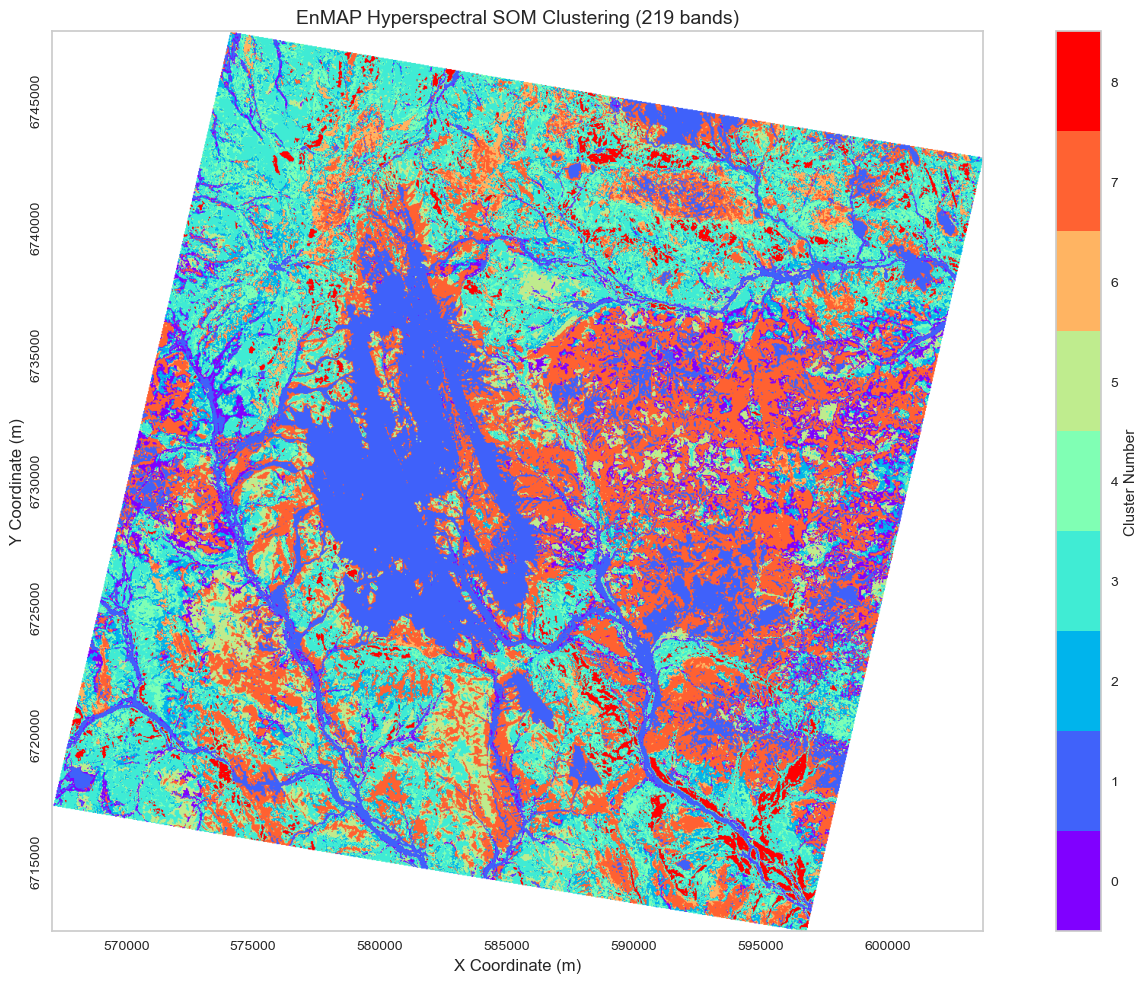


Image statistics:
  Labels image shape: (1182, 1223)
  Valid pixels in image: 1044103
  NaN pixels in image: 401483


In [13]:
# Plot results
def plot_map(array, extent, n_clusters, title="Clustering Results"):
    fig, ax = plt.subplots(figsize=(15, 10))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    plt.yticks(rotation=90, va='center')
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    
    cmap = cm.get_cmap('rainbow', n_clusters)
    cmap.set_bad(color='white')  # Display NaN pixels as white
    
    im = plt.imshow(array, cmap=cmap, extent=extent)
    cbar = plt.colorbar(im, label='Cluster Number')
    
    tick_locs = (np.arange(n_clusters) + 0.5)*(n_clusters-1)/n_clusters
    cbar.set_ticks(tick_locs)
    cbar.set_ticklabels(np.arange(n_clusters))
    
    plt.grid(False)
    plt.xlabel('X Coordinate (m)', fontsize=12)
    plt.ylabel('Y Coordinate (m)', fontsize=12)
    plt.title(title, fontsize=14)
    plt.tight_layout()

n_clusters = len(np.unique(som_labels))
plot_map(labels_image, extent, n_clusters, "EnMAP Hyperspectral SOM Clustering (219 bands)")
plt.show()

# Check for any issues
print(f"\nImage statistics:")
print(f"  Labels image shape: {labels_image.shape}")
print(f"  Valid pixels in image: {(~np.isnan(labels_image)).sum()}")
print(f"  NaN pixels in image: {np.isnan(labels_image).sum()}")

In [14]:
# SAVE FOR EVALUATION
som_encoded = []
for sample in data_valid:
    winner = som.winner(sample)
    som_encoded.append([winner[0], winner[1]])
som_encoded = np.array(som_encoded)

np.save('som_encoded_data.npy', som_encoded)
np.save('som_labels_spatial.npy', labels_image)
print(f"✓ Saved SOM results")

✓ Saved SOM results


Testing 8 different hyperparameter configurations
SOM size: 2×2 = 4 clusters (fixed)

[1/8] Standard: σ=1.0, lr=0.5, iter=1000
  Cluster 0: 348,379 pixels (33.4%)
  Cluster 1: 297,674 pixels (28.5%)
  Cluster 2: 186,760 pixels (17.9%)
  Cluster 3: 211,290 pixels (20.2%)

[2/8] Large neighborhood: σ=1.5, lr=0.5, iter=1000
  Cluster 0: 170,836 pixels (16.4%)
  Cluster 1: 211,151 pixels (20.2%)
  Cluster 2: 165,955 pixels (15.9%)
  Cluster 3: 496,161 pixels (47.5%)

[3/8] Small neighborhood: σ=0.5, lr=0.5, iter=1000
  Cluster 0: 310,951 pixels (29.8%)
  Cluster 1: 332,392 pixels (31.8%)
  Cluster 2: 186,641 pixels (17.9%)
  Cluster 3: 214,119 pixels (20.5%)

[4/8] Low learning rate: σ=1.0, lr=0.1, iter=1000
  Cluster 0: 219,551 pixels (21.0%)
  Cluster 1: 448,500 pixels (43.0%)
  Cluster 2: 232,462 pixels (22.3%)
  Cluster 3: 143,590 pixels (13.8%)

[5/8] High learning rate: σ=1.0, lr=0.8, iter=1000
  Cluster 0: 218,705 pixels (20.9%)
  Cluster 1: 163,969 pixels (15.7%)
  Cluster 2: 319,3

/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_19681/1381279459.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow', 4)  # 4 clusters
/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_19681/1381279459.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow', 4)  # 4 clusters
/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_19681/1381279459.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap(

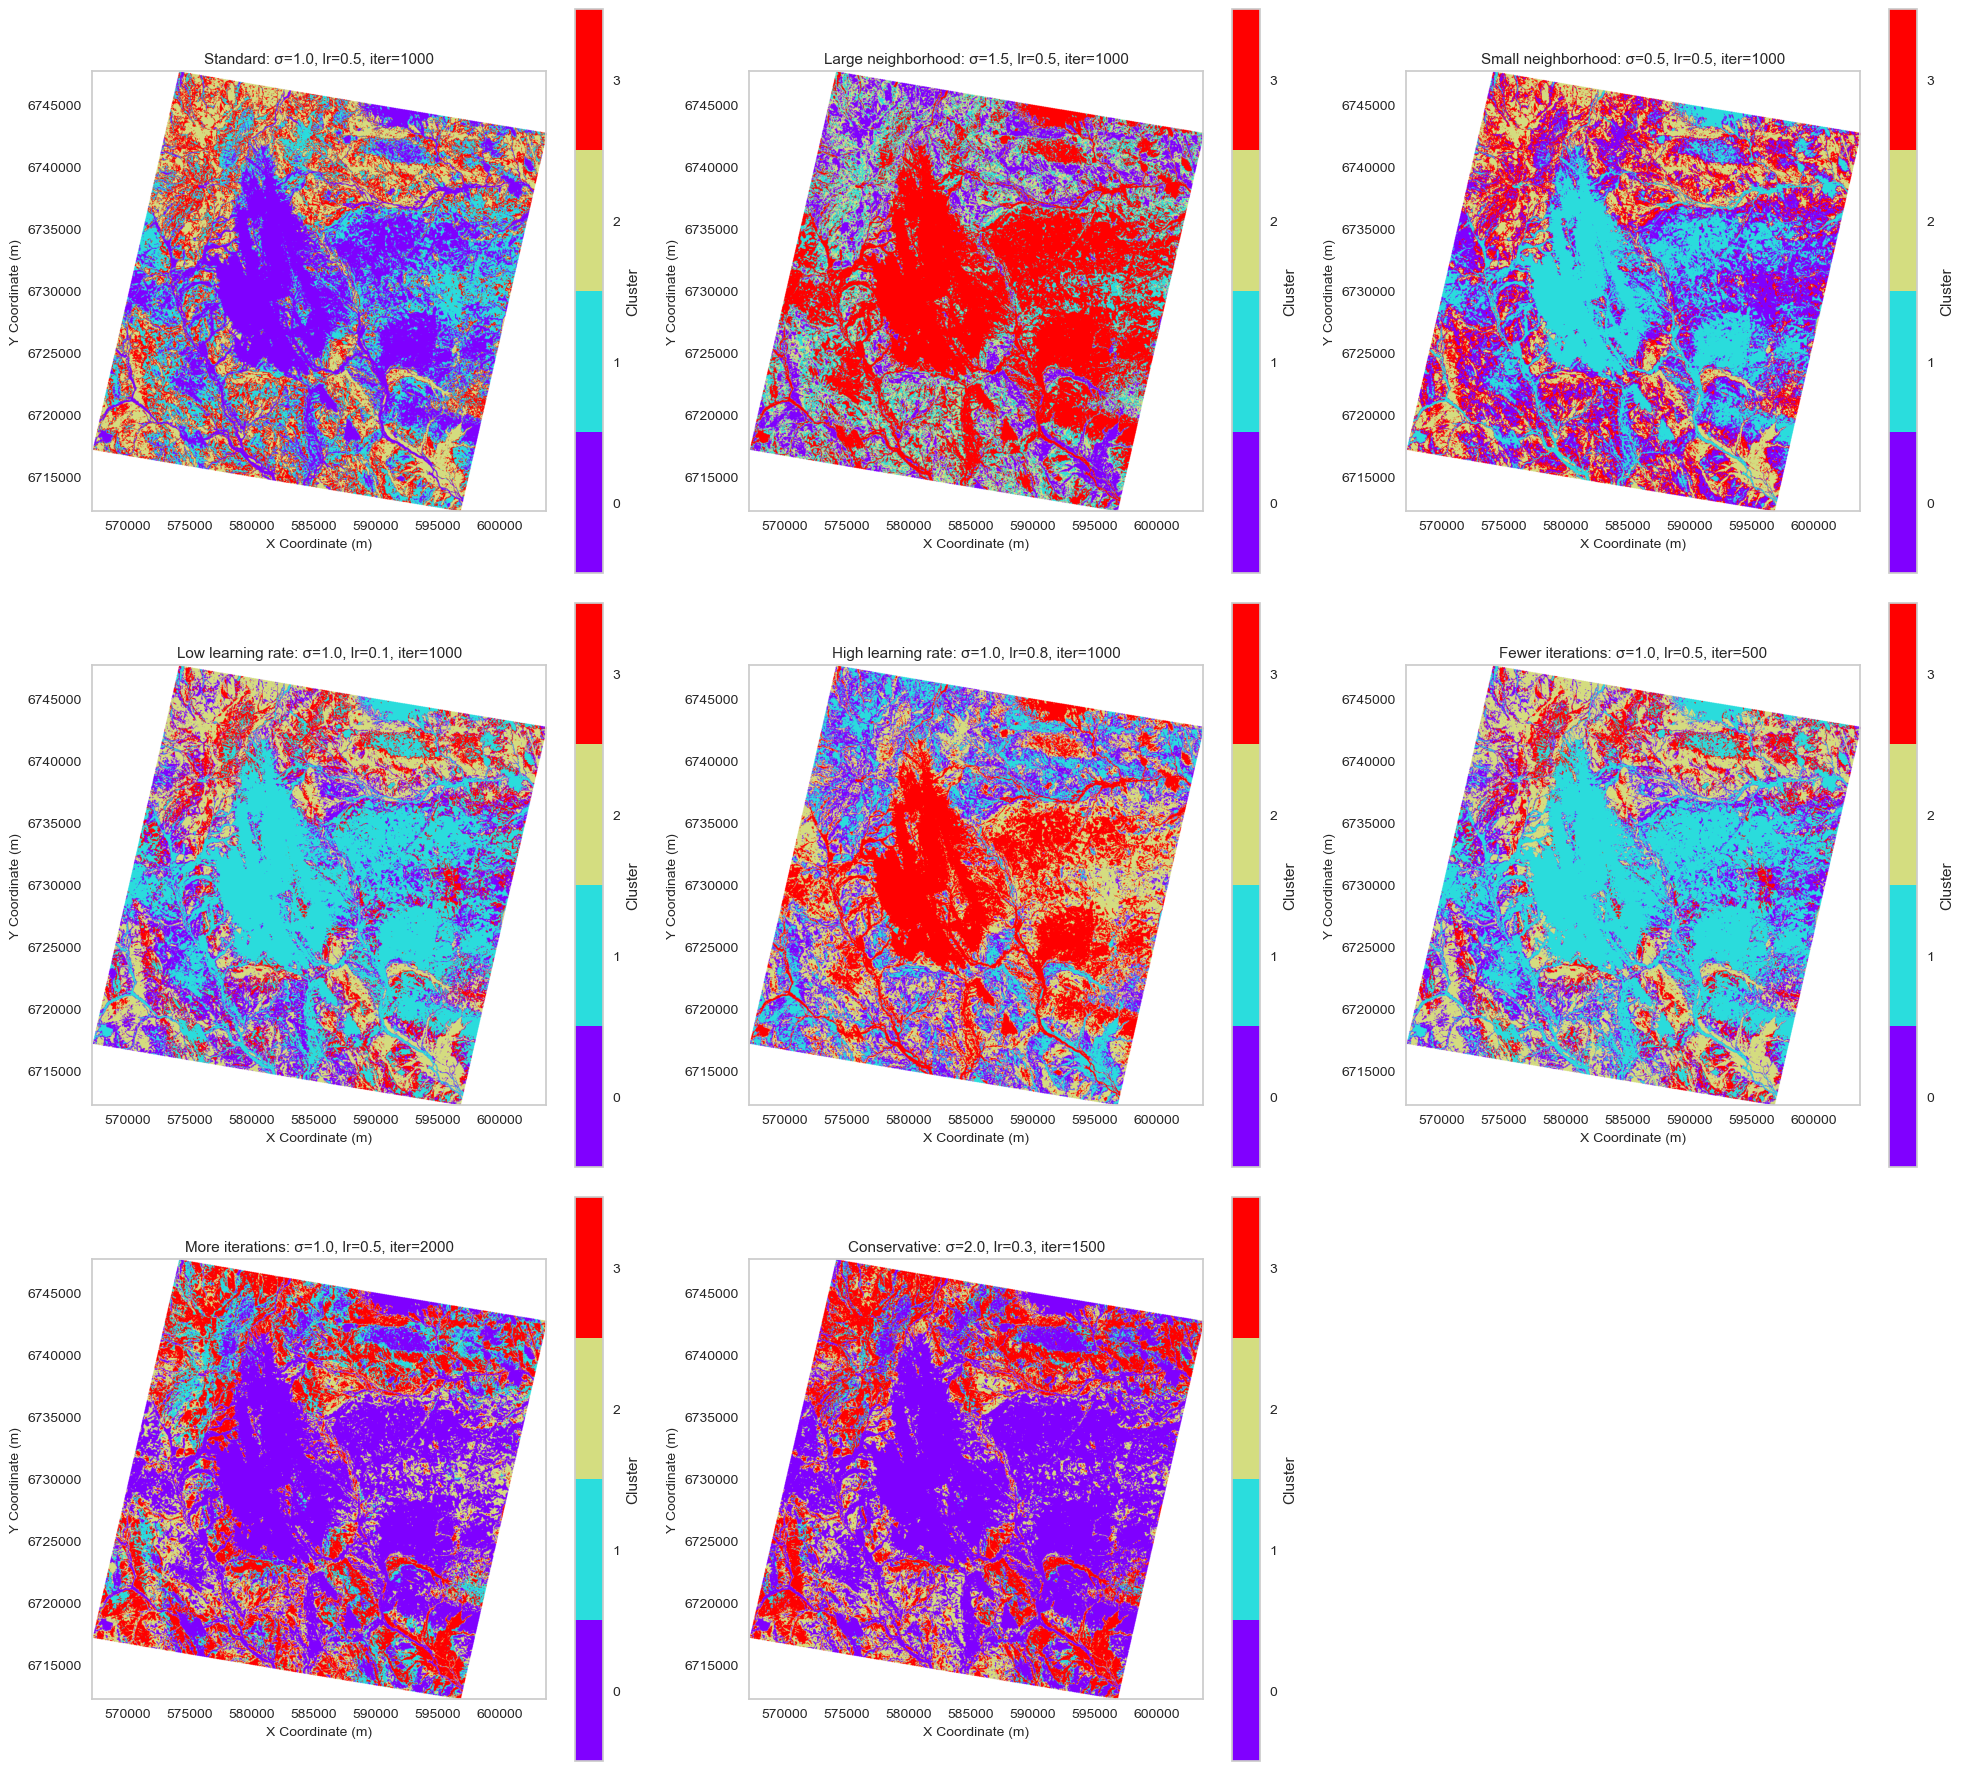

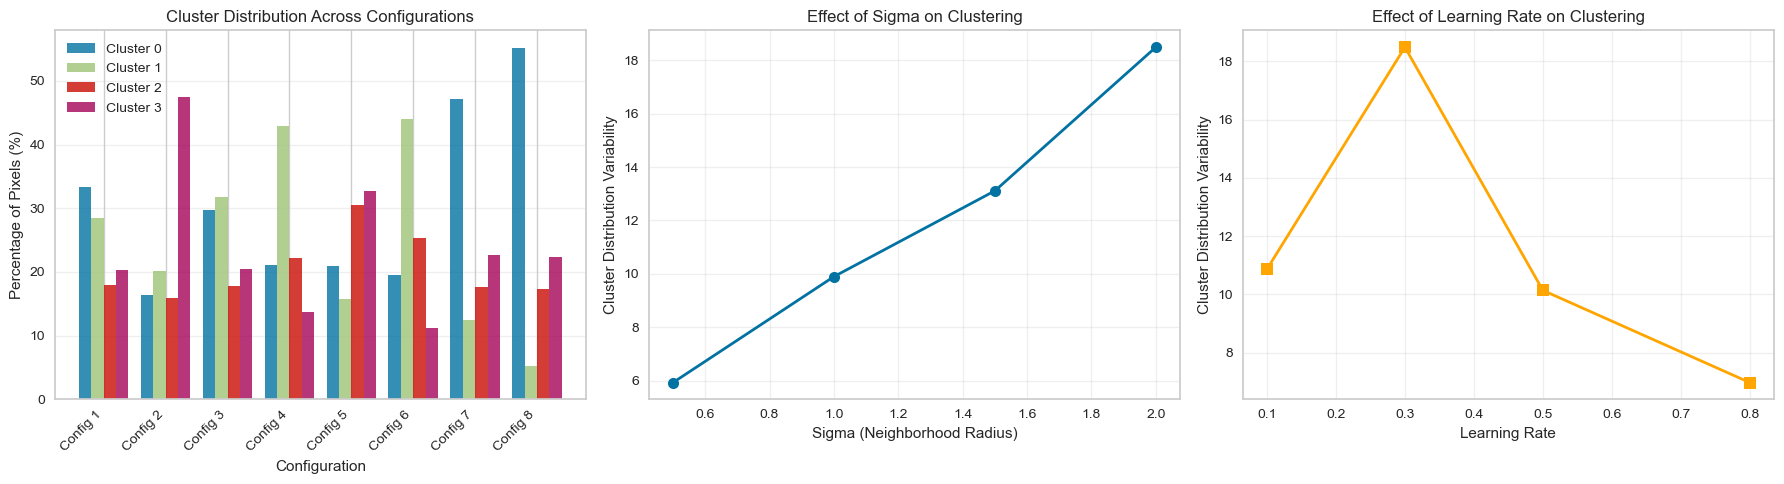


SUMMARY OF RESULTS

Configuration 1: Standard: σ=1.0, lr=0.5, iter=1000
  Hyperparameters: σ=1.0, lr=0.5, iter=1000
  Cluster balance (std dev of percentages): 6.24%
  Largest cluster: 0 with 33.4% of pixels

Configuration 2: Large neighborhood: σ=1.5, lr=0.5, iter=1000
  Hyperparameters: σ=1.5, lr=0.5, iter=1000
  Cluster balance (std dev of percentages): 13.11%
  Largest cluster: 3 with 47.5% of pixels

Configuration 3: Small neighborhood: σ=0.5, lr=0.5, iter=1000
  Hyperparameters: σ=0.5, lr=0.5, iter=1000
  Cluster balance (std dev of percentages): 5.93%
  Largest cluster: 1 with 31.8% of pixels

Configuration 4: Low learning rate: σ=1.0, lr=0.1, iter=1000
  Hyperparameters: σ=1.0, lr=0.1, iter=1000
  Cluster balance (std dev of percentages): 10.86%
  Largest cluster: 1 with 43.0% of pixels

Configuration 5: High learning rate: σ=1.0, lr=0.8, iter=1000
  Hyperparameters: σ=1.0, lr=0.8, iter=1000
  Cluster balance (std dev of percentages): 6.97%
  Largest cluster: 3 with 32.8% of p

In [44]:
# Define hyperparameter configurations to test
configurations = [
    # (sigma, learning_rate, num_iterations, description)
    (1.0, 0.5, 1000, "Standard: σ=1.0, lr=0.5, iter=1000"),
    (1.5, 0.5, 1000, "Large neighborhood: σ=1.5, lr=0.5, iter=1000"),
    (0.5, 0.5, 1000, "Small neighborhood: σ=0.5, lr=0.5, iter=1000"),
    (1.0, 0.1, 1000, "Low learning rate: σ=1.0, lr=0.1, iter=1000"),
    (1.0, 0.8, 1000, "High learning rate: σ=1.0, lr=0.8, iter=1000"),
    (1.0, 0.5, 500, "Fewer iterations: σ=1.0, lr=0.5, iter=500"),
    (1.0, 0.5, 2000, "More iterations: σ=1.0, lr=0.5, iter=2000"),
    (2.0, 0.3, 1500, "Conservative: σ=2.0, lr=0.3, iter=1500"),
]

# Fixed SOM size
som_width = 2
som_height = 2
input_len = data_valid.shape[1]

# Store results for comparison
results = []

print("="*70)
print(f"Testing {len(configurations)} different hyperparameter configurations")
print(f"SOM size: {som_width}×{som_height} = 4 clusters (fixed)")
print("="*70)

# Test each configuration
for config_idx, (sigma, learning_rate, num_iterations, description) in enumerate(configurations):
    print(f"\n[{config_idx+1}/{len(configurations)}] {description}")
    
    # Initialize SOM
    som = MiniSom(som_width, som_height, input_len, 
                  sigma=sigma, 
                  learning_rate=learning_rate,
                  neighborhood_function='gaussian', 
                  random_seed=42)
    
    # Train SOM
    som.random_weights_init(data_valid)
    som.train_batch(data_valid, num_iteration=num_iterations, verbose=False)
    
    # Get cluster labels
    som_labels = get_som_clusters(som, data_valid)
    
    # Create full label array with NaN for invalid pixels
    labels_full = np.full(rows * cols, np.nan)
    labels_full[valid_mask_full] = som_labels
    labels_image = labels_full.reshape(rows, cols)
    
    # Calculate cluster statistics
    cluster_stats = {}
    for cluster_id in np.unique(som_labels):
        count = np.sum(som_labels == cluster_id)
        percentage = (count / len(som_labels)) * 100
        cluster_stats[cluster_id] = {'count': count, 'percentage': percentage}
        print(f"  Cluster {cluster_id}: {count:,} pixels ({percentage:.1f}%)")
    
    # Store results
    results.append({
        'sigma': sigma,
        'learning_rate': learning_rate,
        'num_iterations': num_iterations,
        'description': description,
        'labels_image': labels_image,
        'cluster_stats': cluster_stats,
        'som_labels': som_labels
    })

print("\n" + "="*70)
print("All configurations tested! Generating comparison plots...")
print("="*70)

# Plot all results in a grid
n_configs = len(configurations)
n_cols = 3  # 3 columns
n_rows = int(np.ceil(n_configs / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 6*n_rows))
axes = axes.flatten() if n_configs > 1 else [axes]

for idx, result in enumerate(results):
    ax = axes[idx]
    
    # Create colormap
    cmap = cm.get_cmap('rainbow', 4)  # 4 clusters
    cmap.set_bad(color='white')
    
    # Plot
    im = ax.imshow(result['labels_image'], cmap=cmap, extent=extent)
    
    # Format axes
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    ax.set_xlabel('X Coordinate (m)', fontsize=10)
    ax.set_ylabel('Y Coordinate (m)', fontsize=10)
    ax.set_title(result['description'], fontsize=11, wrap=True)
    ax.grid(False)
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax, label='Cluster')
    tick_locs = (np.arange(4) + 0.5) * 3 / 4
    cbar.set_ticks(tick_locs)
    cbar.set_ticklabels(np.arange(4))

# Hide extra subplots
for idx in range(n_configs, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.savefig('som_hyperparameter_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Create a summary statistics plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Cluster distribution comparison
ax1 = axes[0]
x_pos = np.arange(len(results))
width = 0.2

for cluster_id in range(4):
    percentages = [r['cluster_stats'].get(cluster_id, {'percentage': 0})['percentage'] 
                   for r in results]
    ax1.bar(x_pos + cluster_id * width, percentages, width, 
            label=f'Cluster {cluster_id}', alpha=0.8)

ax1.set_xlabel('Configuration')
ax1.set_ylabel('Percentage of Pixels (%)')
ax1.set_title('Cluster Distribution Across Configurations')
ax1.set_xticks(x_pos + width * 1.5)
ax1.set_xticklabels([f'Config {i+1}' for i in range(len(results))], rotation=45, ha='right')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Plot 2: Effect of sigma
ax2 = axes[1]
sigmas = [r['sigma'] for r in results]
unique_sigmas = sorted(set(sigmas))
sigma_diversity = []

for sigma_val in unique_sigmas:
    configs_with_sigma = [r for r in results if r['sigma'] == sigma_val]
    # Calculate diversity (standard deviation of cluster percentages)
    all_percentages = []
    for r in configs_with_sigma:
        percentages = [r['cluster_stats'].get(i, {'percentage': 0})['percentage'] 
                      for i in range(4)]
        all_percentages.append(np.std(percentages))
    sigma_diversity.append(np.mean(all_percentages))

ax2.plot(unique_sigmas, sigma_diversity, 'o-', linewidth=2, markersize=8)
ax2.set_xlabel('Sigma (Neighborhood Radius)')
ax2.set_ylabel('Cluster Distribution Variability')
ax2.set_title('Effect of Sigma on Clustering')
ax2.grid(True, alpha=0.3)

# Plot 3: Effect of learning rate
ax3 = axes[2]
learning_rates = [r['learning_rate'] for r in results]
unique_lrs = sorted(set(learning_rates))
lr_diversity = []

for lr_val in unique_lrs:
    configs_with_lr = [r for r in results if r['learning_rate'] == lr_val]
    all_percentages = []
    for r in configs_with_lr:
        percentages = [r['cluster_stats'].get(i, {'percentage': 0})['percentage'] 
                      for i in range(4)]
        all_percentages.append(np.std(percentages))
    lr_diversity.append(np.mean(all_percentages))

ax3.plot(unique_lrs, lr_diversity, 's-', linewidth=2, markersize=8, color='orange')
ax3.set_xlabel('Learning Rate')
ax3.set_ylabel('Cluster Distribution Variability')
ax3.set_title('Effect of Learning Rate on Clustering')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('som_hyperparameter_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# Print summary
print("\n" + "="*70)
print("SUMMARY OF RESULTS")
print("="*70)

for idx, result in enumerate(results):
    print(f"\nConfiguration {idx+1}: {result['description']}")
    print(f"  Hyperparameters: σ={result['sigma']}, lr={result['learning_rate']}, iter={result['num_iterations']}")
    print(f"  Cluster balance (std dev of percentages): {np.std([s['percentage'] for s in result['cluster_stats'].values()]):.2f}%")
    most_common = max(result['cluster_stats'].items(), key=lambda x: x[1]['count'])
    print(f"  Largest cluster: {most_common[0]} with {most_common[1]['percentage']:.1f}% of pixels")

print("\n✓ All comparison plots saved!")
print("  - som_hyperparameter_comparison.png (visual comparison)")
print("  - som_hyperparameter_analysis.png (statistical analysis)")